In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.22.0-rc1
NumPy version: 2.5.3


In [4]:
# Dataset paths
faces_path = r"C:/Python-ML/data/siamese_cnn/ollivetti/olivetti_faces.npy"

labels_path = r"C:/Python-ML/data/siamese_cnn/olivetti_faces_target.npy"

# Load dataset
face_images = np.load(faces_path)
face_labels = np.load(labels_path)

print("Images shape:", face_images.shape)
print("Labels shape:", face_labels.shape)

Images shape: (400, 64, 64)
Labels shape: (400,)


In [5]:
print("Data type:", face_images.dtype)
print("Minimum pixel value:", face_images.min())
print("Maximum pixel value:", face_images.max())

print("Number of images:", len(face_images))
print("Number of people:", len(np.unique(face_labels)))

unique_labels, image_counts = np.unique(
    face_labels,
    return_counts=True
)

print("Images per person:", image_counts)

Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Number of images: 400
Number of people: 40
Images per person: [10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]


In [6]:
# Convert to float32
face_images = face_images.astype("float32")

# Normalize pixel values to the range 0–1
if face_images.max() > 1.0:
    face_images = face_images / 255.0

# Add the channel dimension
face_images = np.expand_dims(face_images, axis=-1)

print("Processed image shape:", face_images.shape)

Processed image shape: (400, 64, 64, 1)


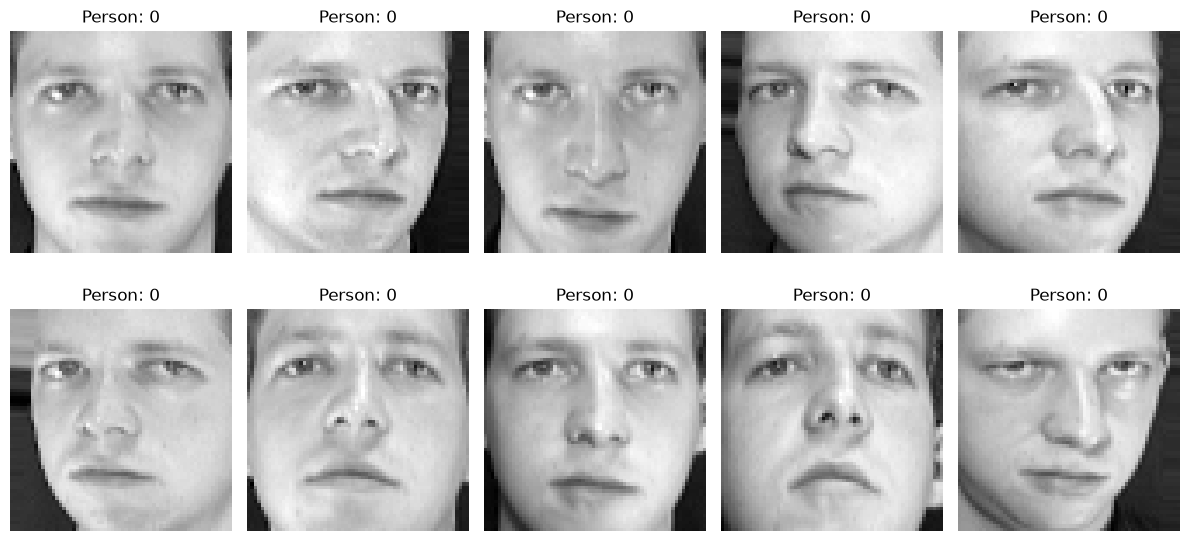

In [7]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(face_images[i].squeeze(), cmap="gray")

    plt.title(f"Person: {face_labels[i]}")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Get all unique identities
unique_people = np.unique(face_labels)

# Split training identities from the remaining identities
train_people, remaining_people = train_test_split(
    unique_people,
    test_size=0.30,
    random_state=SEED
)

# Split remaining identities into validation and testing
val_people, test_people = train_test_split(
    remaining_people,
    test_size=0.50,
    random_state=SEED
)

print("Training identities:", len(train_people))
print("Validation identities:", len(val_people))
print("Testing identities:", len(test_people))

Training identities: 28
Validation identities: 6
Testing identities: 6


In [9]:
train_mask = np.isin(face_labels, train_people)
val_mask = np.isin(face_labels, val_people)
test_mask = np.isin(face_labels, test_people)

X_train = face_images[train_mask]
y_train = face_labels[train_mask]

X_val = face_images[val_mask]
y_val = face_labels[val_mask]

X_test = face_images[test_mask]
y_test = face_labels[test_mask]

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

Training images: (280, 64, 64, 1)
Validation images: (60, 64, 64, 1)
Testing images: (60, 64, 64, 1)


In [10]:
print("Train/Validation overlap:",
      np.intersect1d(np.unique(y_train), np.unique(y_val)))

print("Train/Test overlap:",
      np.intersect1d(np.unique(y_train), np.unique(y_test)))

print("Validation/Test overlap:",
      np.intersect1d(np.unique(y_val), np.unique(y_test)))

Train/Validation overlap: []
Train/Test overlap: []
Validation/Test overlap: []


In [11]:
def generate_image_pairs(images, labels, seed=42):

    rng = np.random.default_rng(seed)

    unique_labels = np.unique(labels)

    # Store the image indexes belonging to each identity
    label_indices = {
        label: np.where(labels == label)[0]
        for label in unique_labels
    }

    pairs = []
    pair_labels = []

    for index, image in enumerate(images):

        current_label = labels[index]

        # -----------------------------
        # Positive pair: same identity
        # -----------------------------

        positive_candidates = label_indices[current_label]

        # Exclude the current image itself
        positive_candidates = positive_candidates[
            positive_candidates != index
        ]

        positive_index = rng.choice(positive_candidates)

        positive_image = images[positive_index]

        pairs.append((image, positive_image))
        pair_labels.append(1)


        # -----------------------------
        # Negative pair: different identity
        # -----------------------------

        negative_candidates = np.where(
            labels != current_label
        )[0]

        negative_index = rng.choice(negative_candidates)

        negative_image = images[negative_index]

        pairs.append((image, negative_image))
        pair_labels.append(0)

    pairs = np.asarray(pairs, dtype="float32")

    pair_labels = np.asarray(
        pair_labels,
        dtype="float32"
    ).reshape(-1, 1)

    # Shuffle the generated pairs
    indices = rng.permutation(len(pairs))

    return pairs[indices], pair_labels[indices]

In [12]:
train_pairs, train_pair_labels = generate_image_pairs(
    X_train, y_train, seed=SEED
)

val_pairs, val_pair_labels = generate_image_pairs(
    X_val, y_val, seed=SEED + 1
)

test_pairs, test_pair_labels = generate_image_pairs(
    X_test, y_test, seed=SEED + 2
)

print("Training pairs:", train_pairs.shape)
print("Validation pairs:", val_pairs.shape)
print("Testing pairs:", test_pairs.shape)

Training pairs: (560, 2, 64, 64, 1)
Validation pairs: (120, 2, 64, 64, 1)
Testing pairs: (120, 2, 64, 64, 1)


In [13]:
print(
    "Training pair distribution:",
    np.unique(train_pair_labels, return_counts=True)
)

print(
    "Validation pair distribution:",
    np.unique(val_pair_labels, return_counts=True)
)

print(
    "Testing pair distribution:",
    np.unique(test_pair_labels, return_counts=True)
)

Training pair distribution: (array([0., 1.], dtype=float32), array([280, 280]))
Validation pair distribution: (array([0., 1.], dtype=float32), array([60, 60]))
Testing pair distribution: (array([0., 1.], dtype=float32), array([60, 60]))


In [14]:
def visualize_pairs(pairs, labels, number=5):

    plt.figure(figsize=(10, number * 2))

    for i in range(number):

        image_a = pairs[i, 0].squeeze()
        image_b = pairs[i, 1].squeeze()

        label = int(labels[i][0])

        plt.subplot(number, 2, 2 * i + 1)
        plt.imshow(image_a, cmap="gray")
        plt.title("Image A")
        plt.axis("off")

        plt.subplot(number, 2, 2 * i + 2)
        plt.imshow(image_b, cmap="gray")
        plt.title(
            "Image B - " + ("Same Person" if label == 1 else "Different Person")
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

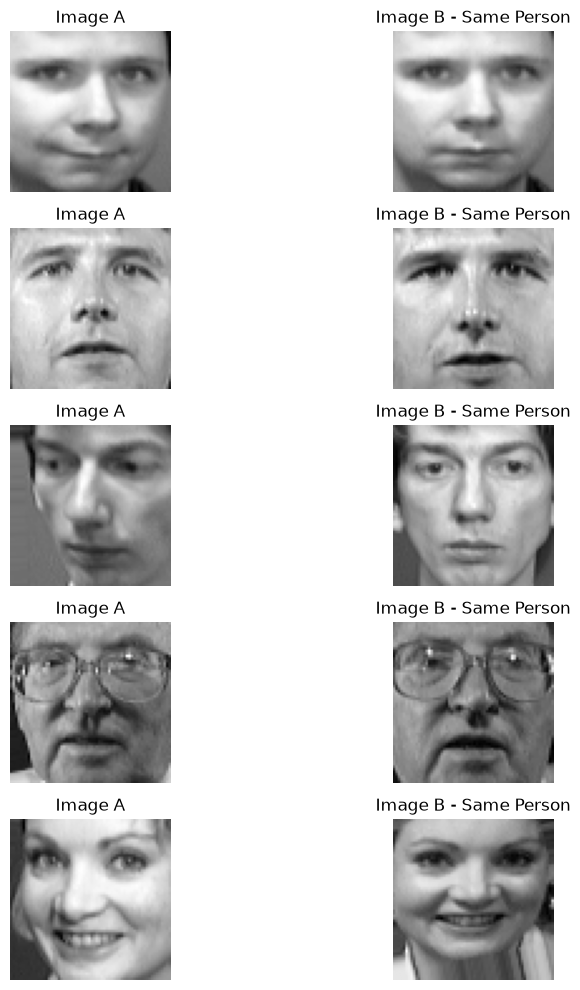

In [15]:
visualize_pairs(train_pairs, train_pair_labels)

In [16]:
def build_embedding_model():

    inputs = layers.Input(shape=(64, 64, 1))

    # First convolution block
    x = layers.Conv2D(
        32,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(inputs)

    x = layers.MaxPooling2D(pool_size=2)(x)

    # Second convolution block
    x = layers.Conv2D(
        64,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D(pool_size=2)(x)

    # Third convolution block
    x = layers.Conv2D(
        128,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D(pool_size=2)(x)

    # Convert feature maps into a vector
    x = layers.GlobalAveragePooling2D()(x)

    # Create the embedding
    x = layers.Dense(128)(x)

    # Normalize embedding vectors
    outputs = layers.Lambda(
        lambda tensor: tf.math.l2_normalize(tensor, axis=1),
        name="embedding_normalization"
    )(x)

    embedding_model = Model(
        inputs=inputs,
        outputs=outputs,
        name="Embedding"
    )

    return embedding_model

In [17]:
embedding = build_embedding_model()

embedding.summary()

Model: "Embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 64, 64, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding_normalization (Lambda)     │ (None, 128)                 │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,184 (426.50 KB)

 Trainable params: 109,184 (426.50 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
class DistanceLayer(layers.Layer):

    def call(self, anchor, compare):

        squared_difference = tf.square(anchor - compare)

        summed_squared_difference = tf.reduce_sum(
            squared_difference,
            axis=1,
            keepdims=True
        )

        distance = tf.sqrt(
            tf.maximum(summed_squared_difference, 1e-10)
        )

        return distance

In [19]:
def contrastive_loss(y_true, distances, margin=1.0):

    y_true = tf.cast(y_true, distances.dtype)

    # Same-person pairs should have small distances
    positive_loss = y_true * tf.square(distances)

    # Different-person pairs should be separated by the margin
    negative_loss = (1 - y_true) * tf.square(
        tf.maximum(margin - distances, 0)
    )

    loss = tf.reduce_mean(
        positive_loss + negative_loss
    )

    return loss

In [20]:
def build_siamese_model(embedding_model):

    # Input for the first image
    anchor_input = layers.Input(
        shape=(64, 64, 1),
        name="anchor"
    )

    # Input for the second image
    compare_input = layers.Input(
        shape=(64, 64, 1),
        name="compare"
    )

    # Pass both images through the SAME embedding model
    anchor_embedding = embedding_model(anchor_input)

    compare_embedding = embedding_model(compare_input)

    # Calculate distance between embeddings
    distance = DistanceLayer()(
        anchor_embedding,
        compare_embedding
    )

    siamese_model = Model(
        inputs=[anchor_input, compare_input],
        outputs=distance,
        name="SiameseNetwork"
    )

    return siamese_model

In [21]:
siamese_model = build_siamese_model(embedding)

siamese_model.summary()

Model: "SiameseNetwork"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ anchor (InputLayer)           │ (None, 64, 64, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ compare (InputLayer)          │ (None, 64, 64, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Embedding (Functional)        │ (None, 128)               │         109,184 │ anchor[0][0],              │
│                               │                           │                 │ compare[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distance_layer                │ (None, 1)                 │               0 │ Embedding[0][0],           │
│ (DistanceLayer)               │                           │                 │ Embedding[1][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 109,184 (426.50 KB)

 Trainable params: 109,184 (426.50 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
siamese_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss=contrastive_loss
)

In [23]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.000001
)

In [25]:
history = siamese_model.fit(
    [
        train_pairs[:, 0],
        train_pairs[:, 1]
    ],
    train_pair_labels,

    validation_data=(
        [
            val_pairs[:, 0],
            val_pairs[:, 1]
        ],
        val_pair_labels
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    shuffle=True
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 237ms/step - loss: 0.1175 - val_loss: 0.1696 - learning_rate: 1.0000e-04
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 229ms/step - loss: 0.1141 - val_loss: 0.1651 - learning_rate: 1.0000e-04
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - loss: 0.1152 - val_loss: 0.1652 - learning_rate: 1.0000e-04
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 272ms/step - loss: 0.1132 - val_loss: 0.1463 - learning_rate: 1.0000e-04
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 236ms/step - loss: 0.1048 - val_loss: 0.1356 - learning_rate: 1.0000e-04
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 240ms/step - loss: 0.1010 - val_loss: 0.1320 - learning_rate: 1.0000e-04
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 251ms/step - loss: 0.0966 - val_loss: 0.1317 - learning_rate: 1.0000e-04
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 230ms/step - loss: 0.0946 - val_loss: 0.1309 - learning_rate: 1.0000e-04
Epoch 9/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 232ms/step - loss: 0.0914 - val_loss: 

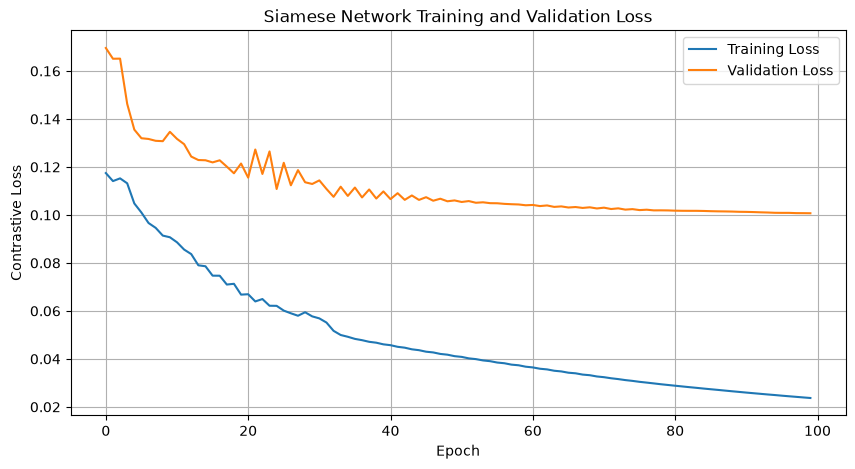

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Siamese Network Training and Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Contrastive Loss")

plt.legend()
plt.grid(True)

plt.show()

In [27]:
val_distances = siamese_model.predict(
    [
        val_pairs[:, 0],
        val_pairs[:, 1]
    ]
)

test_distances = siamese_model.predict(
    [
        test_pairs[:, 0],
        test_pairs[:, 1]
    ]
)

print("Validation distances:", val_distances[:10].flatten())
print("Test distances:", test_distances[:10].flatten())

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Validation distances: [0.32936168 0.40271544 1.2063673  0.7824366  0.9910728  0.18522198
 0.37565428 0.91476727 0.5523941  0.8753582 ]
Test distances: [0.33736226 0.75882214 0.8250746  0.4144507  1.2433093  1.095233
 0.8543024  0.7309634  0.52027076 0.40351537]


In [28]:
thresholds = np.linspace(0.05, 2.0, 400)

best_threshold = 0
best_score = 0

for threshold in thresholds:

    val_predictions = (
        val_distances.flatten() <= threshold
    ).astype(int)

    score = balanced_accuracy_score(
        val_pair_labels.flatten(),
        val_predictions
    )

    if score > best_score:
        best_score = score
        best_threshold = threshold

print("Best validation threshold:", best_threshold)
print("Validation balanced accuracy:", best_score)

Best validation threshold: 0.5533834586466166
Validation balanced accuracy: 0.9333333333333333


In [29]:
test_predictions = (
    test_distances.flatten() <= best_threshold
).astype(int)

test_accuracy = accuracy_score(
    test_pair_labels.flatten(),
    test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    test_pair_labels.flatten(),
    test_predictions
)

print("Test Accuracy:", test_accuracy)
print("Test Balanced Accuracy:", test_balanced_accuracy)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        test_pair_labels.flatten(),
        test_predictions
    )
)

print("\nClassification Report:")
print(
    classification_report(
        test_pair_labels.flatten(),
        test_predictions,
        target_names=["Different Person", "Same Person"]
    )
)

Test Accuracy: 0.7833333333333333
Test Balanced Accuracy: 0.7833333333333333

Confusion Matrix:
[[55  5]
 [21 39]]

Classification Report:
                  precision    recall  f1-score   support

Different Person       0.72      0.92      0.81        60
     Same Person       0.89      0.65      0.75        60

        accuracy                           0.78       120
       macro avg       0.81      0.78      0.78       120
    weighted avg       0.81      0.78      0.78       120



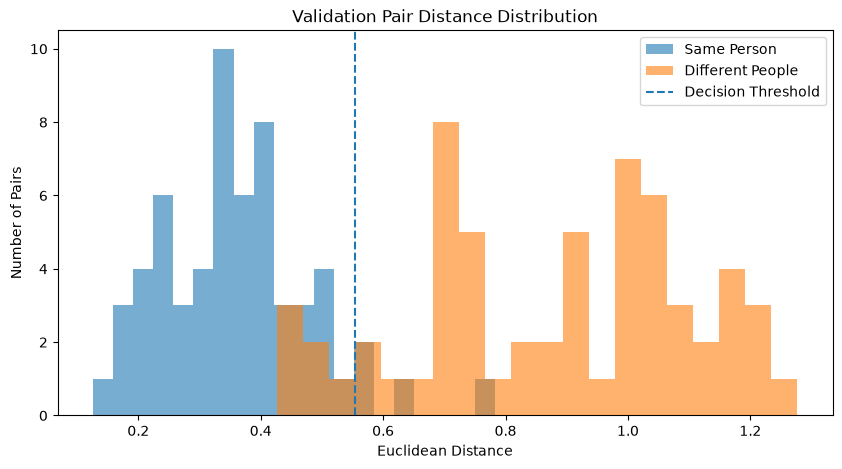

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(
    val_distances[val_pair_labels == 1].flatten(),
    bins=20,
    alpha=0.6,
    label="Same Person"
)

plt.hist(
    val_distances[val_pair_labels == 0].flatten(),
    bins=20,
    alpha=0.6,
    label="Different People"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Decision Threshold"
)

plt.title("Validation Pair Distance Distribution")

plt.xlabel("Euclidean Distance")
plt.ylabel("Number of Pairs")

plt.legend()
plt.show()

In [31]:
def compare_faces(image_a, image_b):

    image_a = np.asarray(image_a, dtype="float32")
    image_b = np.asarray(image_b, dtype="float32")

    if image_a.ndim == 2:
        image_a = np.expand_dims(image_a, axis=-1)

    if image_b.ndim == 2:
        image_b = np.expand_dims(image_b, axis=-1)

    if image_a.shape != (64, 64, 1):
        raise ValueError("Image A must have shape (64, 64, 1)")

    if image_b.shape != (64, 64, 1):
        raise ValueError("Image B must have shape (64, 64, 1)")

    image_a = np.expand_dims(image_a, axis=0)
    image_b = np.expand_dims(image_b, axis=0)

    distance = siamese_model.predict(
        [image_a, image_b],
        verbose=0
    )[0][0]

    prediction = (
        "Same Person"
        if distance <= best_threshold
        else "Different People"
    )

    return {
        "distance": float(distance),
        "prediction": prediction
    }

In [108]:
from torchcodec.decoders import decode_image
from torch import nn
from torchvision import transforms 

PATH = "C:/Python-ML/data/profile_match/"
IMAGE_1 = "1.jpg"
IMAGE_2 = "2.jpg"
IMAGE_3 = "3.png"
IMAGE_4 = "4.jpg"
IMAGE_5 = "5.jpg"
IMAGE_6 = "6.jpg"
IMAGE_7 = "7.jpg"

DAFAULT_PATH = PATH

def ProcessImage(path: str) -> torch.Tensor:

    image = decode_image(path)

    transform_image = nn.Sequential(
        transforms.Resize(size=(64, 64)),
        transforms.Grayscale(num_output_channels=1)
    )

    image_transform = transform_image(image)
    image_transform = image_transform.float() / 255.0

    reshape_image = image_transform.permute(1, 2, 0)

    return reshape_image

get_image_1 = ProcessImage(DAFAULT_PATH + IMAGE_1)
get_image_2 = ProcessImage(DAFAULT_PATH + IMAGE_6)

get_image_1.shape, get_image_2.shape

(torch.Size([64, 64, 1]), torch.Size([64, 64, 1]))

torch.Size([64, 64, 1])
{'distance': 1.0914268493652344, 'prediction': 'Different People'}


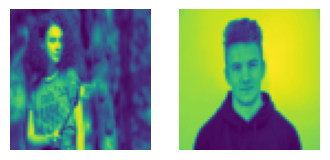

In [109]:
# plt.subplot()
image_1 = get_image_1
image_2 = get_image_2

print(image_1.shape)

fig = plt.figure(figsize = (4,4))
fig.add_subplot(1,2,1)
plt.imshow(image_1)
plt.axis(False)

fig.add_subplot(1,2,2)
plt.imshow(image_2)
plt.axis(False)

result = compare_faces(
    image_1,
    image_2
)

print(result)

In [110]:
os.makedirs("saved_models", exist_ok=True)

siamese_model.save(
    "saved_models/siamese_face_model.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [111]:
# Load the model
# loaded_model = tf.keras.models.load_model(
#     "saved_models/siamese_face_model.keras",
#     custom_objects={
#         "DistanceLayer": DistanceLayer,
#         "contrastive_loss": contrastive_loss
#     }
# )